In [ ]:
import pandas as pd # Importing Pandas library

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
path="/content/drive/MyDrive/Colab Notebooks/GSCopy.csv"
df=pd.read_csv(path) # To read the CSV file in Colab?
df.head(7) # To read the 1st 7 rows of the excel csv file?
df.tail(7)

,Name,Yearly,IIL,NCFI,RBA,COR,SGA,OE,OEBIE,OPNRI,...,TL,LOAN,IS,DFIH,LR,INV,TA,PAE,TAP,TSE
24,GS,1999,"17,396","8,503.00","32,427","16,410","10,952","27,362","10,952","5,065.00",...,"293,987",NaN,"49,992","38,818","33,463","70,067","312,218","97,297","97,297","18,231"
25,GS,1998,"12,722","6,437.00","24,917","12,018","10,693","22,911","10,893","2,006.00",...,"267,880",NaN,"37,634","35,059","39,286","59,115","284,410","82,148","82,148","16,530"
26,GS,1997,"15,010","5,029.00","22,054","13,958","5,175.00","19,133","5,175.00","2,921.00",...,"240,346",NaN,"34,205","31,223","34,630","50,586","250,491","59,534","59,534","10,145"
27,GS,1996,"14,087","3,686.00","20,076","12,986","4,076.00","17,062","4,076.00","3,014.00",...,"210,996",NaN,"37,833","21,780","19,274","48,899","217,380","46,938","46,938","6,384.00"
28,GS,1995,"11,699","2,816.00","17,011","11,160","3,245.00","14,405","3,245.00","2,606.00",...,"171,864",NaN,"39,639","14,880","13,814","51,509","178,401","23,947","23,947","6,537.00"
29,GS,1994,"14,324",NaN,"14,324","9,841.00","2,005.00","12,956","3,115.00","1,368.00",...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,GS,1993,"12,452",NaN,"12,452","8,915.00","1,789.00","11,944","3,029.00",508,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
#import libraries & perform logistic regression
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,
random_state=23)
clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train, y_train)
acc = accuracy_score(y_test, clf.predict(X_test)) * 100
print(f"Logistic Regression model accuracy: {acc:.2f}%")

Logistic Regression model accuracy: 96.49%


In [ ]:
# Visualize the dataset using PCA
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
X, y = load_breast_cancer(return_X_y=True)

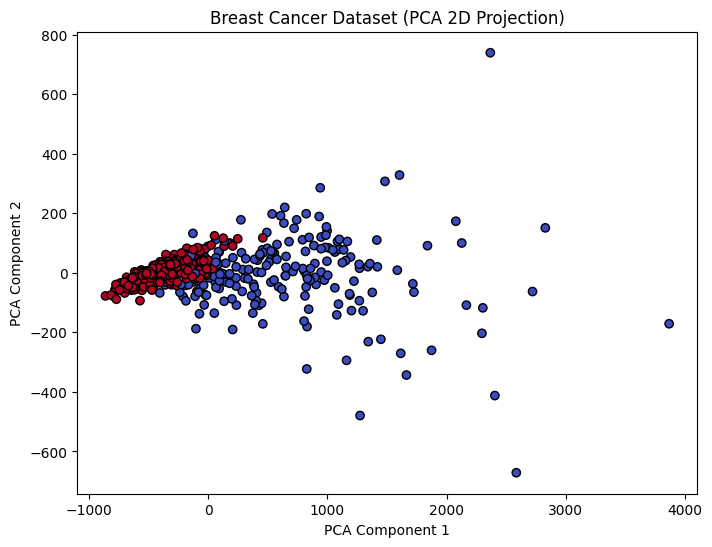

In [ ]:
# Reduce to 2D for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=y, cmap='coolwarm', edgecolor='k')
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Breast Cancer Dataset (PCA 2D Projection)")
plt.show()

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [ ]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.20, random_state=23
)
clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train, y_train)
acc = accuracy_score(y_test, clf.predict(X_test)) * 100
print(f"Logistic Regression model accuracy: {acc:.2f}%")


Logistic Regression model accuracy: 96.49%


In [ ]:
# Project training data into PCA space
X_train_pca = pca.transform(X_train)


In [ ]:
# Create mesh grid for decision boundary
x_min, x_max = X_pca[:,0].min() - 1, X_pca[:,0].max() + 1
y_min, y_max = X_pca[:,1].min() - 1, X_pca[:,1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
np.linspace(y_min, y_max, 300))

In [ ]:
# Inverse transform grid back to original feature space
grid = np.c_[xx.ravel(), yy.ravel()]
grid_original = pca.inverse_transform(grid)

In [ ]:
# Predict on grid
Z = clf.predict(grid_original).reshape(xx.shape)

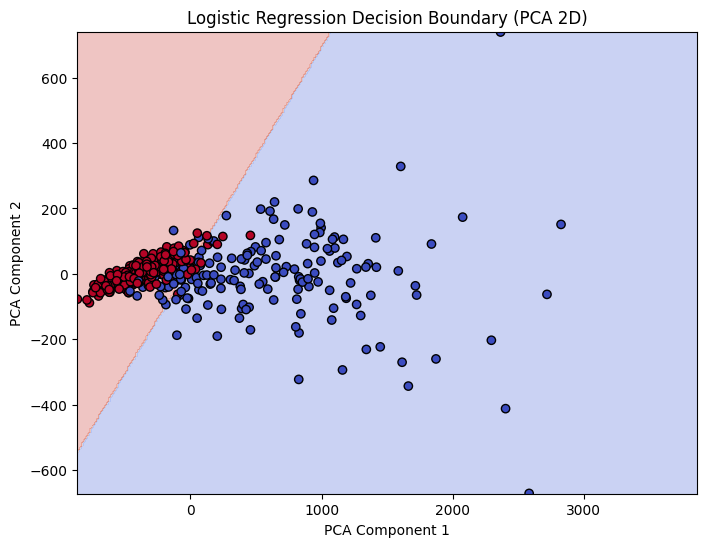

In [ ]:
# Plot
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=y_train, cmap='coolwarm', edgecolor='k')
plt.title("Logistic Regression Decision Boundary (PCA 2D)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
 n_estimators=200,
 random_state=0
)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test)) * 100
print(f"Random Forest model accuracy: {rf_acc:.2f}%")

Random Forest model accuracy: 97.37%


In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(
 n_estimators=200,
 random_state=0
)
rf.fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test)) * 100
print(f"Random Forest model accuracy: {rf_acc:.2f}%")

Random Forest model accuracy: 97.37%


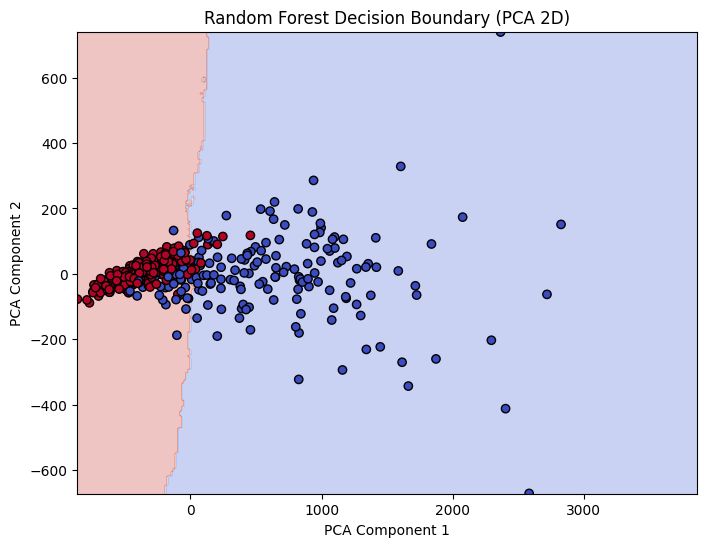

In [ ]:
# Predict on PCA grid using Random Forest
Z_rf = rf.predict(grid_original).reshape(xx.shape)
plt.figure(figsize=(8,6))
plt.contourf(xx, yy, Z_rf, alpha=0.3, cmap='coolwarm')
plt.scatter(X_train_pca[:,0], X_train_pca[:,1], c=y_train, cmap='coolwarm', edgecolor='k')
plt.title("Random Forest Decision Boundary (PCA 2D)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

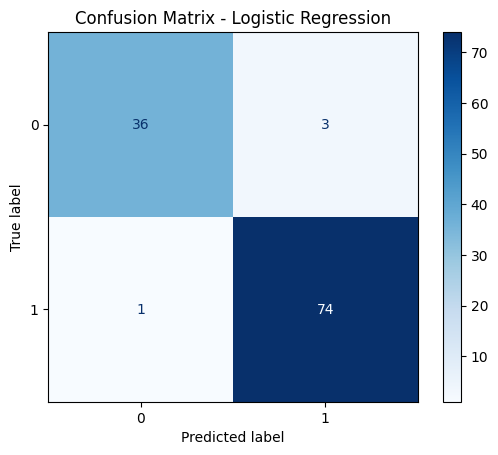

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_test, clf.predict(X_test))
disp_lr = ConfusionMatrixDisplay(cm_lr)
disp_lr.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

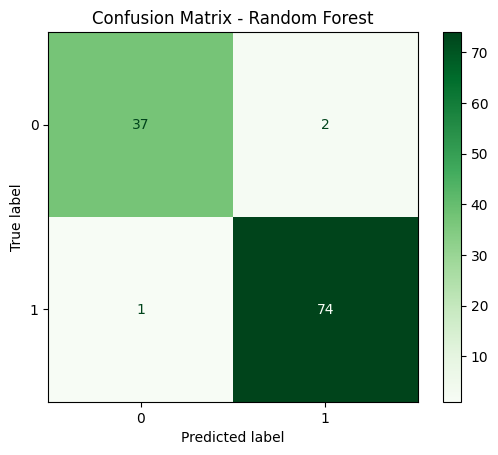

In [ ]:
# Random Forest confusion matrix
cm_rf = confusion_matrix(y_test, rf.predict(X_test))
disp_rf = ConfusionMatrixDisplay(cm_rf)
disp_rf.plot(cmap="Greens")
plt.title("Confusion Matrix - Random Forest")
plt.show()

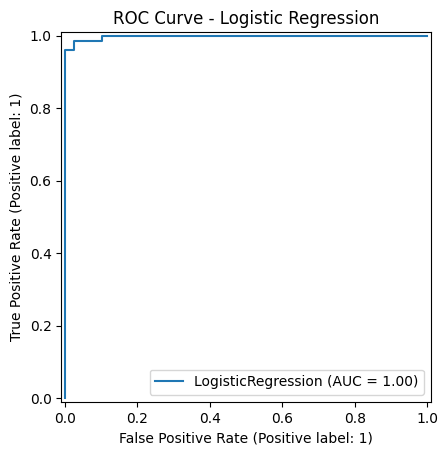

In [ ]:
from sklearn.metrics import RocCurveDisplay
# Logistic Regression ROC
RocCurveDisplay.from_estimator(clf, X_test, y_test)
plt.title("ROC Curve - Logistic Regression")
plt.show()

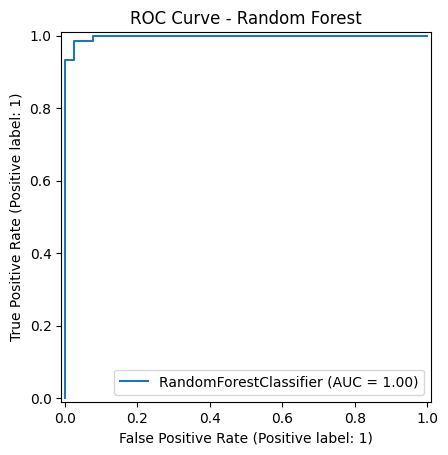

In [ ]:
# Random Forest ROC
RocCurveDisplay.from_estimator(rf, X_test, y_test)
plt.title("ROC Curve - Random Forest")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn import datasets, linear_model, metrics
digits = datasets.load_digits()
X = digits.data
y = digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1)
reg = linear_model.LogisticRegression(max_iter=10000, random_state=0)
reg.fit(X_train, y_train)
y_pred = reg.predict(X_test)
print(f"Logistic Regression model accuracy: {metrics.accuracy_score(y_test, y_pred) *
100:.2f}%")

Logistic Regression model accuracy: 96.66%
